# Introduction

<center><img src="https://i.imgur.com/9hLRsjZ.jpg" height=400></center>

This dataset was scraped from [nextspaceflight.com](https://nextspaceflight.com/launches/past/?page=1) and includes all the space missions since the beginning of Space Race between the USA and the Soviet Union in 1957!

### Install Package with Country Codes

In [20]:
%pip install iso3166


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Upgrade Plotly

Run the cell below if you are working with Google Colab.

In [1]:
%pip install --upgrade plotly

  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [plotly]━━━━ 1/2 [plotly]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3.13 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Import Statements

In [22]:
%pip install numpy pandas plotly matplotlib seaborn iso3166

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 2.8 MB/s  0:00:01m 2.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 5.9 MB/s  0:00:01a 0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 7.9 MB/s  0:00:018.1 MB/s eta 0:00:01:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 8.3 MB/s  0:00:005.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 11.2 MB/s  0:00:00 11.6 MB/s eta 0:00:01
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [seaborn]━  9/10 [seaborn]ib]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3

In [26]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

# These might be helpful:
from iso3166 import countries
from datetime import datetime, timedelta

### Notebook Presentation

In [28]:
pd.options.display.float_format = '{:,.2f}'.format

### Load the Data

In [29]:
df_data = pd.read_csv('mission_launches.csv')

# Preliminary Data Exploration

* What is the shape of `df_data`? 
* How many rows and columns does it have?
* What are the column names?
* Are there any NaN values or duplicates?

In [32]:
print("Dataset Shape:", df_data.shape)
print("\nNumber of Rows:", df_data.shape[0])
print("Number of Columns:", df_data.shape[1])
print("\nColumn Names:")
print(df_data.columns.tolist())

Dataset Shape: (4324, 9)

Number of Rows: 4324
Number of Columns: 9

Column Names:
['Unnamed: 0.1', 'Unnamed: 0', 'Organisation', 'Location', 'Date', 'Detail', 'Rocket_Status', 'Price', 'Mission_Status']


In [33]:
df_data.head()

,Unnamed: 0.1,Unnamed: 0,Organisation,Location,Date,Detail,Rocket_Status,Price,Mission_Status
0,0,0,SpaceX,"LC-39A, Kennedy Space Center, Florida, USA","Fri Aug 07, 2020 05:12 UTC",Falcon 9 Block 5 | Starlink V1 L9 & BlackSky,StatusActive,50.0,Success
1,1,1,CASC,"Site 9401 (SLS-2), Jiuquan Satellite Launch Ce...","Thu Aug 06, 2020 04:01 UTC",Long March 2D | Gaofen-9 04 & Q-SAT,StatusActive,29.75,Success
2,2,2,SpaceX,"Pad A, Boca Chica, Texas, USA","Tue Aug 04, 2020 23:57 UTC",Starship Prototype | 150 Meter Hop,StatusActive,NaN,Success
3,3,3,Roscosmos,"Site 200/39, Baikonur Cosmodrome, Kazakhstan","Thu Jul 30, 2020 21:25 UTC",Proton-M/Briz-M | Ekspress-80 & Ekspress-103,StatusActive,65.0,Success
4,4,4,ULA,"SLC-41, Cape Canaveral AFS, Florida, USA","Thu Jul 30, 2020 11:50 UTC",Atlas V 541 | Perseverance,StatusActive,145.0,Success


In [34]:
df_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4324 entries, 0 to 4323
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Unnamed: 0.1    4324 non-null   int64
 1   Unnamed: 0      4324 non-null   int64
 2   Organisation    4324 non-null   str  
 3   Location        4324 non-null   str  
 4   Date            4324 non-null   str  
 5   Detail          4324 non-null   str  
 6   Rocket_Status   4324 non-null   str  
 7   Price           964 non-null    str  
 8   Mission_Status  4324 non-null   str  
dtypes: int64(2), str(7)
memory usage: 304.2 KB


## Data Cleaning - Check for Missing Values and Duplicates

Consider removing columns containing junk data. 

In [35]:
# Check missing values in each column
df_data.isna().sum()

Unnamed: 0.1         0
Unnamed: 0           0
Organisation         0
Location             0
Date                 0
Detail               0
Rocket_Status        0
Price             3360
Mission_Status       0
dtype: int64

In [37]:
print("Total duplicate rows:", df_data.duplicated().sum())
df_data.describe(include='all')

Total duplicate rows: 0


,Unnamed: 0.1,Unnamed: 0,Organisation,Location,Date,Detail,Rocket_Status,Price,Mission_Status
count,"4,324.00","4,324.00",4324,4324,4324,4324,4324,964,4324
unique,NaN,NaN,56,137,4319,4278,2,56,4
top,NaN,NaN,RVSN USSR,"Site 31/6, Baikonur Cosmodrome, Kazakhstan","Wed Nov 05, 2008 00:15 UTC",Cosmos-3MRB (65MRB) | BOR-5 Shuttle,StatusRetired,450.0,Success
freq,NaN,NaN,1777,235,2,6,3534,136,3879
mean,"2,161.50","2,161.50",NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,"1,248.38","1,248.38",NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,"1,080.75","1,080.75",NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,"2,161.50","2,161.50",NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,"3,242.25","3,242.25",NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
# Remove unnecessary index columns
df_data = df_data.loc[:, ~df_data.columns.str.contains('^Unnamed')]

# Verify the cleaned dataset
print(df_data.shape)
print(df_data.columns.tolist())

(4324, 7)
['Organisation', 'Location', 'Date', 'Detail', 'Rocket_Status', 'Price', 'Mission_Status']


In [39]:
df_data['Price'].dropna().head(10)

0      50.0
1     29.75
3      65.0
4     145.0
5     64.68
6      48.5
8      50.0
9      90.0
10     46.0
11     28.3
Name: Price, dtype: str

In [40]:
df_data['Price'] = pd.to_numeric(df_data['Price'], errors='coerce')

print(df_data['Price'].dtype)

float64


In [41]:
df_data['Date'] = pd.to_datetime(
    df_data['Date'],
    format='mixed',
    errors='coerce',
    utc=True
)

print(df_data['Date'].dtype)

datetime64[us, UTC]


In [42]:
df_data['Year'] = df_data['Date'].dt.year
df_data['Month'] = df_data['Date'].dt.month

df_data[['Date', 'Year', 'Month']].head()

,Date,Year,Month
0,2020-08-07 05:12:00+00:00,2020,8
1,2020-08-06 04:01:00+00:00,2020,8
2,2020-08-04 23:57:00+00:00,2020,8
3,2020-07-30 21:25:00+00:00,2020,7
4,2020-07-30 11:50:00+00:00,2020,7


## Descriptive Statistics

In [43]:
df_data.describe()

,Price,Year,Month
count,949.00,"4,324.00","4,324.00"
mean,129.80,"1,987.39",6.75
std,143.22,18.07,3.42
min,5.30,"1,957.00",1.00
25%,40.00,"1,972.00",4.00
50%,62.00,"1,984.00",7.00
75%,164.00,"2,002.00",10.00
max,450.00,"2,020.00",12.00


# Number of Launches per Company

Create a chart that shows the number of space mission launches by organisation.

In [44]:
# Count missions by organisation
company_launches = df_data['Organisation'].value_counts()

# Display top 10 organisations
company_launches.head(10)

Organisation
RVSN USSR           1777
Arianespace          279
CASC                 251
General Dynamics     251
NASA                 203
VKS RF               201
US Air Force         161
ULA                  140
Boeing               136
Martin Marietta      114
Name: count, dtype: int64

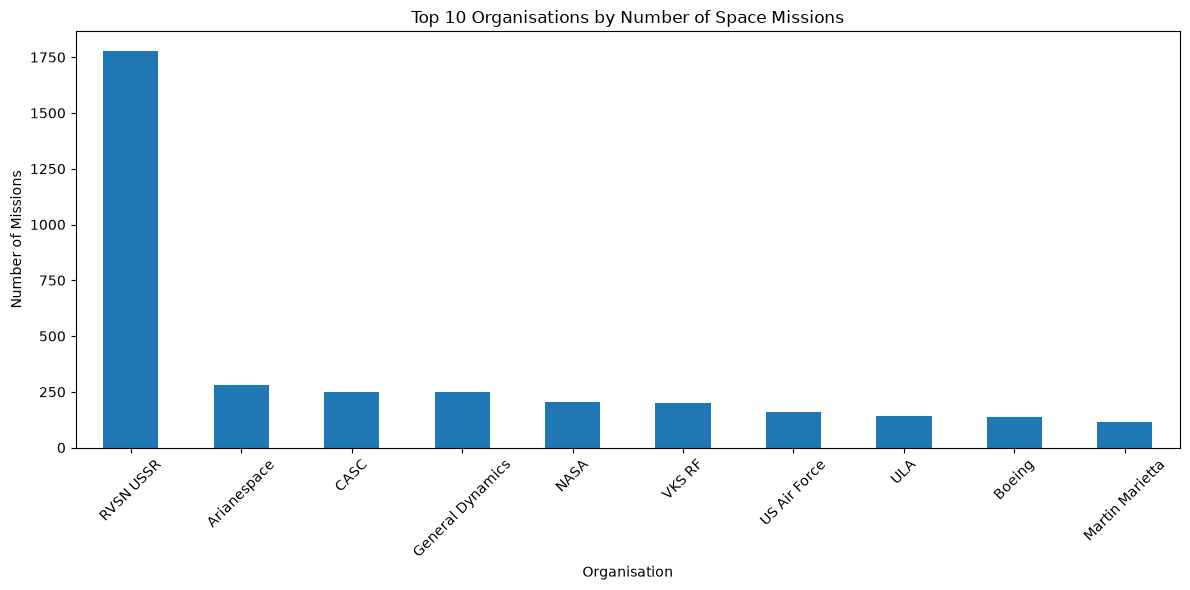

In [45]:
plt.figure(figsize=(12, 6))

company_launches.head(10).plot(kind='bar')

plt.title('Top 10 Organisations by Number of Space Missions')
plt.xlabel('Organisation')
plt.ylabel('Number of Missions')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

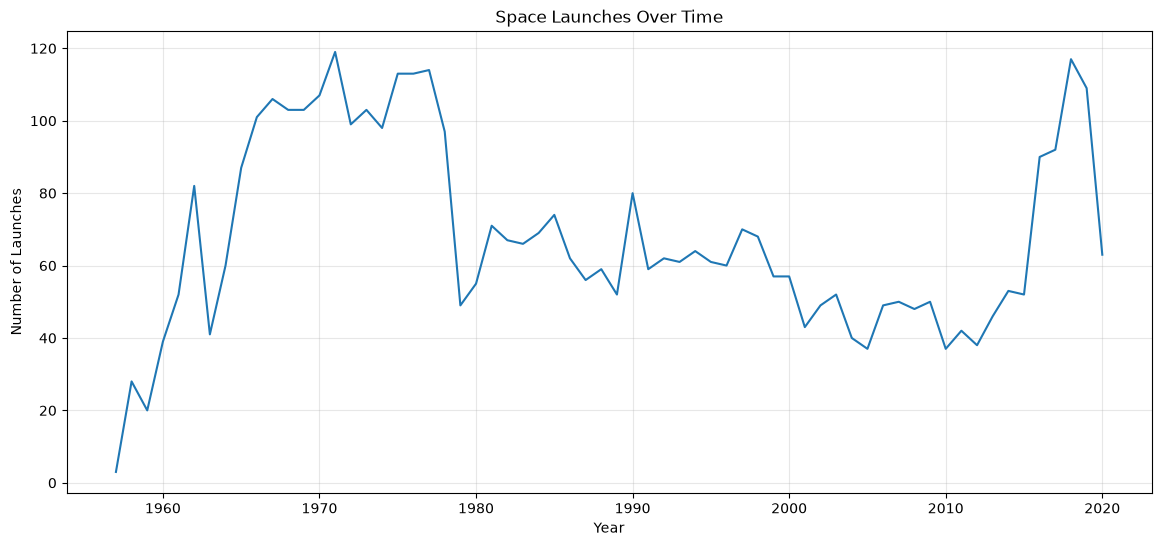

In [46]:
yearly_launches = df_data.groupby('Year').size()

plt.figure(figsize=(14, 6))

plt.plot(yearly_launches.index, yearly_launches.values)

plt.title('Space Launches Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Launches')
plt.grid(True, alpha=0.3)

plt.show()

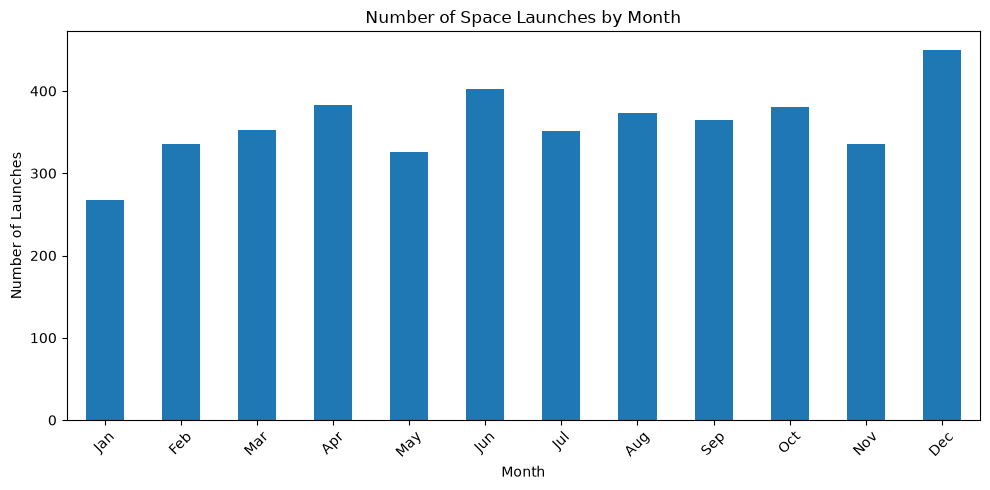

In [47]:
monthly_launches = df_data['Month'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

monthly_launches.plot(kind='bar')

plt.title('Number of Space Launches by Month')
plt.xlabel('Month')
plt.ylabel('Number of Launches')
plt.xticks(range(12), [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
], rotation=45)

plt.tight_layout()
plt.show()

# Number of Active versus Retired Rockets

How many rockets are active compared to those that are decomissioned? 

In [48]:
rocket_status = df_data['Rocket_Status'].value_counts()

print(rocket_status)

Rocket_Status
StatusRetired    3534
StatusActive      790
Name: count, dtype: int64


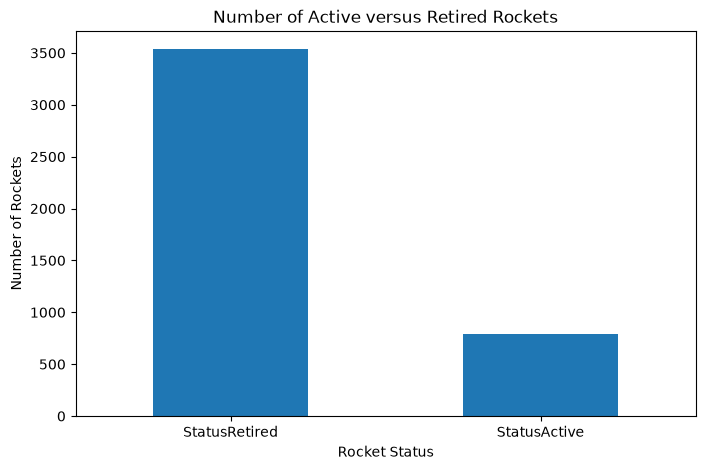

In [49]:
plt.figure(figsize=(8, 5))

rocket_status.plot(kind='bar')

plt.title('Number of Active versus Retired Rockets')
plt.xlabel('Rocket Status')
plt.ylabel('Number of Rockets')
plt.xticks(rotation=0)

plt.show()

# Distribution of Mission Status

How many missions were successful?
How many missions failed?

In [50]:
mission_status = df_data['Mission_Status'].value_counts()

print(mission_status)

Mission_Status
Success              3879
Failure               339
Partial Failure       102
Prelaunch Failure       4
Name: count, dtype: int64


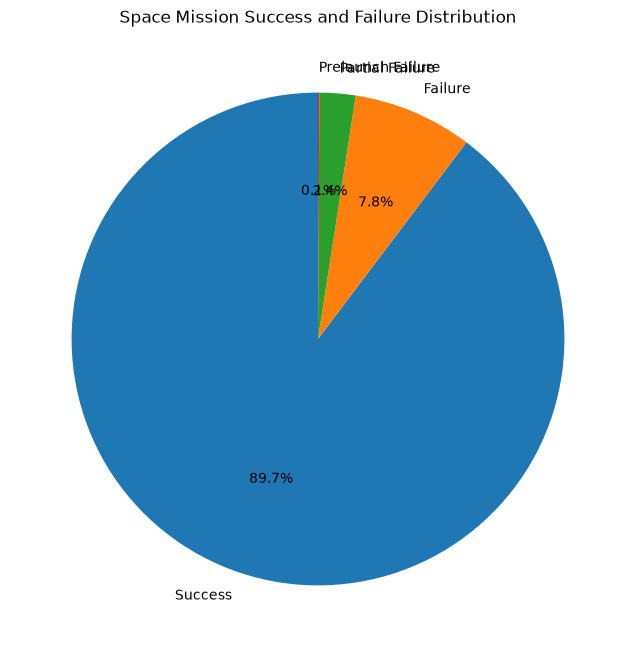

In [51]:
plt.figure(figsize=(8, 8))

mission_status.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Space Mission Success and Failure Distribution')
plt.ylabel('')

plt.show()

# How Expensive are the Launches? 

Create a histogram and visualise the distribution. The price column is given in USD millions (careful of missing values). 

In [52]:
# Remove missing prices for cost analysis
launch_costs = df_data['Price'].dropna()

# Display basic cost statistics
print(launch_costs.describe())

count   949.00
mean    129.80
std     143.22
min       5.30
25%      40.00
50%      62.00
75%     164.00
max     450.00
Name: Price, dtype: float64


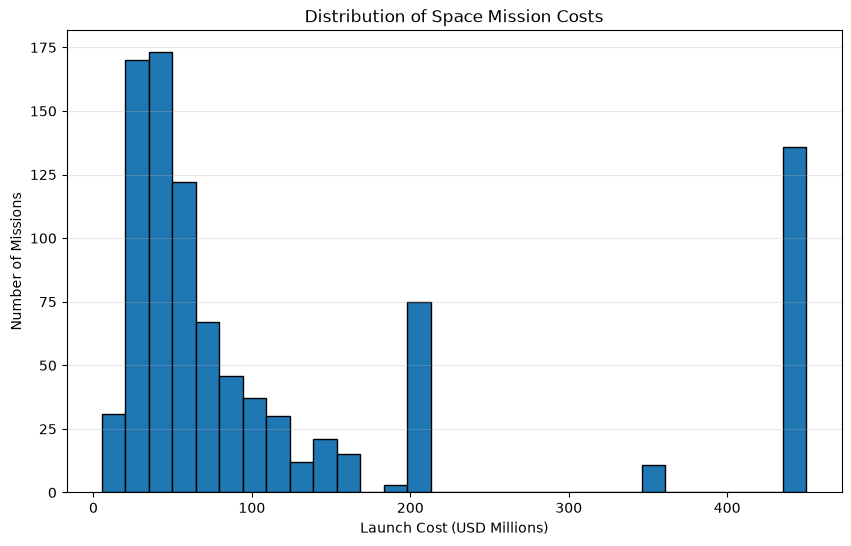

In [53]:
plt.figure(figsize=(10, 6))

plt.hist(launch_costs, bins=30, edgecolor='black')

plt.title('Distribution of Space Mission Costs')
plt.xlabel('Launch Cost (USD Millions)')
plt.ylabel('Number of Missions')

plt.grid(axis='y', alpha=0.3)
plt.show()

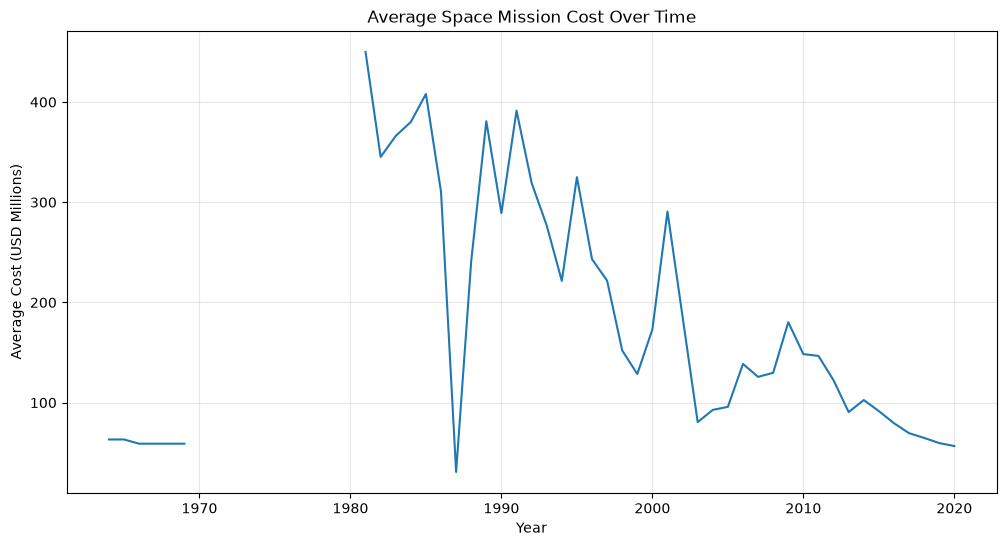

In [54]:
yearly_cost = df_data.groupby('Year')['Price'].mean()

plt.figure(figsize=(12, 6))

plt.plot(yearly_cost.index, yearly_cost.values)

plt.title('Average Space Mission Cost Over Time')
plt.xlabel('Year')
plt.ylabel('Average Cost (USD Millions)')
plt.grid(alpha=0.3)

plt.show()

# Use a Choropleth Map to Show the Number of Launches by Country

* Create a choropleth map using [the plotly documentation](https://plotly.com/python/choropleth-maps/)
* Experiment with [plotly's available colours](https://plotly.com/python/builtin-colorscales/). I quite like the sequential colour `matter` on this map. 
* You'll need to extract a `country` feature as well as change the country names that no longer exist.

Wrangle the Country Names

You'll need to use a 3 letter country code for each country. You might have to change some country names.

* Russia is the Russian Federation
* New Mexico should be USA
* Yellow Sea refers to China
* Shahrud Missile Test Site should be Iran
* Pacific Missile Range Facility should be USA
* Barents Sea should be Russian Federation
* Gran Canaria should be USA


You can use the iso3166 package to convert the country names to Alpha3 format.

In [55]:
# Extract country names from Location
df_data['Country'] = df_data['Location'].str.split(',').str[-1].str.strip()

# Check the most frequent country names
print(df_data['Country'].value_counts().head(25))

Country
Russia                            1395
USA                               1344
Kazakhstan                         701
France                             303
China                              268
Japan                              126
India                               76
Pacific Ocean                       36
New Zealand                         13
Iran                                13
Israel                              11
Kenya                                9
Australia                            6
North Korea                          5
New Mexico                           4
South Korea                          3
Barents Sea                          3
Brazil                               3
Gran Canaria                         2
Shahrud Missile Test Site            1
Yellow Sea                           1
Pacific Missile Range Facility       1
Name: count, dtype: int64


In [56]:
print(sorted(df_data['Country'].dropna().unique()))

['Australia', 'Barents Sea', 'Brazil', 'China', 'France', 'Gran Canaria', 'India', 'Iran', 'Israel', 'Japan', 'Kazakhstan', 'Kenya', 'New Mexico', 'New Zealand', 'North Korea', 'Pacific Missile Range Facility', 'Pacific Ocean', 'Russia', 'Shahrud Missile Test Site', 'South Korea', 'USA', 'Yellow Sea']


In [57]:
country_mapping = {
    'Australia': 'Australia',
    'Brazil': 'Brazil',
    'China': 'China',
    'France': 'France',
    'Gran Canaria': 'Spain',
    'India': 'India',
    'Iran': 'Iran',
    'Israel': 'Israel',
    'Japan': 'Japan',
    'Kazakhstan': 'Kazakhstan',
    'Kenya': 'Kenya',
    'New Mexico': 'USA',
    'New Zealand': 'New Zealand',
    'North Korea': 'North Korea',
    'Pacific Missile Range Facility': 'USA',
    'Shahrud Missile Test Site': 'Iran',
    'South Korea': 'South Korea',
    'Russia': 'Russia',
    'USA': 'USA'
}

df_data['Country_Clean'] = df_data['Country'].map(country_mapping)

print("Unmapped locations:")
print(df_data.loc[df_data['Country_Clean'].isna(), 'Country'].value_counts())

Unmapped locations:
Country
Pacific Ocean    36
Barents Sea       3
Yellow Sea        1
Name: count, dtype: int64


In [59]:
country_codes = {
    'Australia': 'AUS',
    'Brazil': 'BRA',
    'China': 'CHN',
    'France': 'FRA',
    'Spain': 'ESP',
    'India': 'IND',
    'Iran': 'IRN',
    'Israel': 'ISR',
    'Japan': 'JPN',
    'Kazakhstan': 'KAZ',
    'Kenya': 'KEN',
    'USA': 'USA',
    'New Zealand': 'NZL',
    'North Korea': 'PRK',
    'South Korea': 'KOR',
    'Russia': 'RUS'
}

df_data['ISO3'] = df_data['Country_Clean'].map(country_codes)

In [68]:
print(country_launches.shape)
print(country_launches.head(10))
print(country_launches['Launches'].sum())

(16, 3)
  Country_Clean ISO3  Launches
0     Australia  AUS         6
1        Brazil  BRA         3
2         China  CHN       268
3        France  FRA       303
4         India  IND        76
5          Iran  IRN        14
6        Israel  ISR        11
7         Japan  JPN       126
8    Kazakhstan  KAZ       701
9         Kenya  KEN         9
4284


In [70]:
fig = px.choropleth(
    country_launches,
    locations='ISO3',
    color='Launches',
    hover_name='Country_Clean',
    locationmode='ISO-3',
    color_continuous_scale='Viridis',
    title='Number of Space Launches by Country'
)

fig.show(renderer="browser")

# Use a Choropleth Map to Show the Number of Failures by Country


In [71]:
# Filter all unsuccessful missions
failed_missions = df_data[
    df_data['Mission_Status'] != 'Success'
].copy()

print("Total unsuccessful missions:", len(failed_missions))

print(failed_missions['Mission_Status'].value_counts())

Total unsuccessful missions: 445
Mission_Status
Failure              339
Partial Failure      102
Prelaunch Failure      4
Name: count, dtype: int64


In [72]:
# Count failures by country
country_failures = (
    failed_missions
    .dropna(subset=['ISO3'])
    .groupby(['Country_Clean', 'ISO3'])
    .size()
    .reset_index(name='Failures')
    .sort_values('Failures', ascending=False)
)

country_failures.head(10)

,Country_Clean,ISO3,Failures
13,USA,USA,163
8,Kazakhstan,KAZ,93
11,Russia,RUS,92
2,China,CHN,25
3,France,FRA,18
4,India,IND,13
7,Japan,JPN,13
5,Iran,IRN,9
0,Australia,AUS,3
1,Brazil,BRA,3


In [74]:
fig = px.choropleth(
    country_failures,
    locations='ISO3',
    locationmode='ISO-3',
    color='Failures',
    hover_name='Country_Clean',
    hover_data=['Failures'],
    color_continuous_scale='Reds',
    title='Number of Failed Space Missions by Country'
)

fig.show(renderer='browser')

# Create a Plotly Sunburst Chart of the countries, organisations, and mission status. 

In [75]:
sunburst_data = (
    df_data.dropna(subset=['Country_Clean', 'Organisation', 'Mission_Status'])
    .groupby(['Country_Clean', 'Organisation', 'Mission_Status'])
    .size()
    .reset_index(name='Mission_Count')
)

sunburst_data.head(10)

,Country_Clean,Organisation,Mission_Status,Mission_Count
0,Australia,AMBA,Success,1
1,Australia,CECLES,Failure,2
2,Australia,CECLES,Success,1
3,Australia,RAE,Failure,1
4,Australia,RAE,Success,1
5,Brazil,AEB,Failure,2
6,Brazil,AEB,Prelaunch Failure,1
7,China,CASC,Failure,14
8,China,CASC,Partial Failure,6
9,China,CASC,Success,230


In [77]:
fig = px.sunburst(
    sunburst_data,
    path=['Country_Clean', 'Organisation', 'Mission_Status'],
    values='Mission_Count',
    title='Space Missions: Country, Organisation and Mission Status',
    color='Mission_Status',
    color_discrete_map={
        'Success': '#2EAD67',
        'Failure': '#E74C3C',
        'Partial Failure': '#F39C12',
        'Prelaunch Failure': '#8E44AD'
    }
)

fig.update_layout(
    width=1000,
    height=800
)

fig.show(renderer='browser')

### Insights: Space Mission Sunburst Analysis

- Russia and the USA account for substantial portions of the historical mission dataset.
- RVSN USSR is a major contributor to the total mission count.
- Successful missions form the largest portions across major organisations.
- The chart reveals the relationship between countries, organisations and mission outcomes.

# Analyse the Total Amount of Money Spent by Organisation on Space Missions

In [78]:
# Calculate total spending by organisation
organisation_spending = (
    df_data.groupby('Organisation')['Price']
    .sum()
    .sort_values(ascending=False)
)

print(organisation_spending.head(15))

Organisation
NASA              61,200.00
Arianespace       16,345.00
ULA               14,798.00
CASC               6,340.26
SpaceX             5,444.00
Northrop           3,930.00
MHI                3,532.50
ISRO               2,177.00
US Air Force       1,550.92
VKS RF             1,548.90
ILS                1,320.00
Boeing             1,241.00
Roscosmos          1,187.50
Martin Marietta      721.40
Kosmotras            638.00
Name: Price, dtype: float64


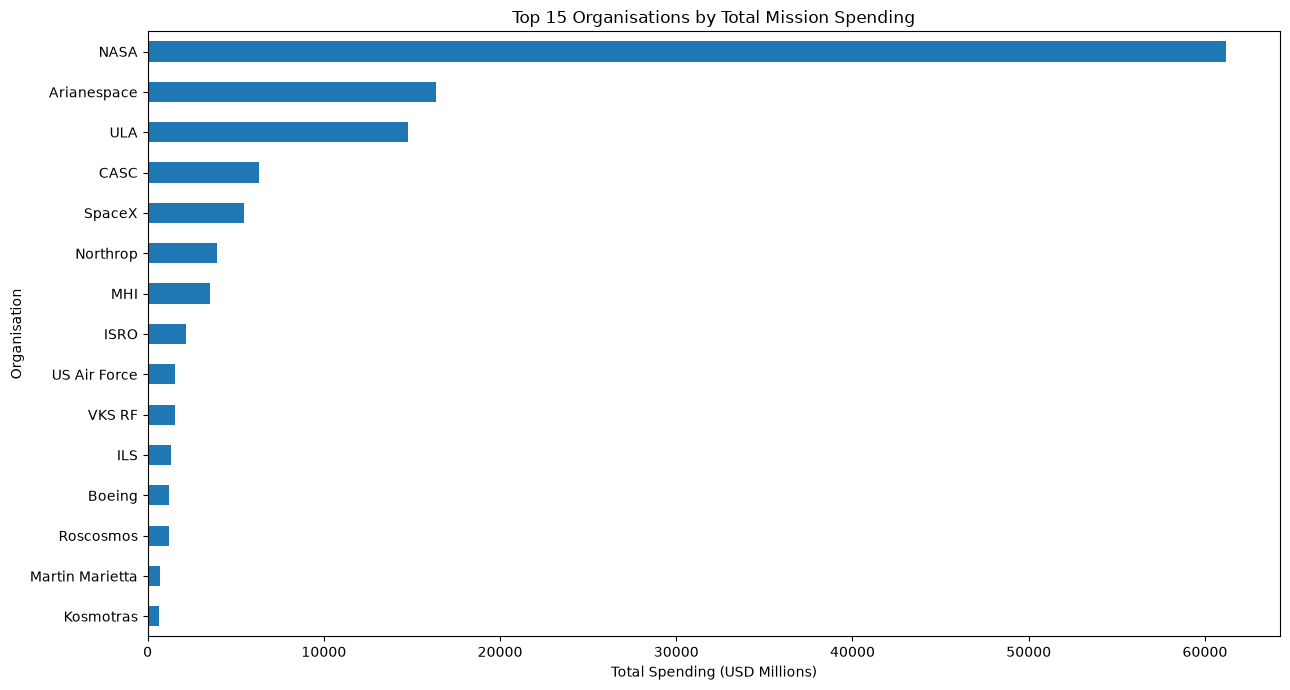

In [79]:
plt.figure(figsize=(13, 7))

organisation_spending.head(15).sort_values().plot(kind='barh')

plt.title('Top 15 Organisations by Total Mission Spending')
plt.xlabel('Total Spending (USD Millions)')
plt.ylabel('Organisation')

plt.tight_layout()
plt.show()

In [85]:
top_spenders = (
    organisation_spending.head(15)
    .reset_index()
)

fig = px.bar(
    top_spenders,
    x='Price',
    y='Organisation',
    orientation='h',
    title='Top 15 Space Organisations by Total Spending',
    labels={
        'Price': 'Total Spending (USD Millions)',
        'Organisation': 'Organisation'
    },
    color='Price',
    color_continuous_scale='Viridis'
)

fig.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    height=650
)

fig.show(renderer='browser')

# Analyse the Amount of Money Spent by Organisation per Launch

In [86]:
organisation_avg_cost = (
    df_data.groupby('Organisation')['Price']
    .mean()
    .dropna()
    .sort_values(ascending=False)
)

print(organisation_avg_cost.head(15))

Organisation
NASA              450.00
Boeing            177.29
Arianespace       170.26
ULA               151.00
ILS               101.54
MHI                95.47
Martin Marietta    80.16
US Air Force       59.65
JAXA               56.00
SpaceX             54.99
Roscosmos          51.63
Northrop           47.35
VKS RF             46.94
Eurockot           41.80
CASC               40.13
Name: Price, dtype: float64


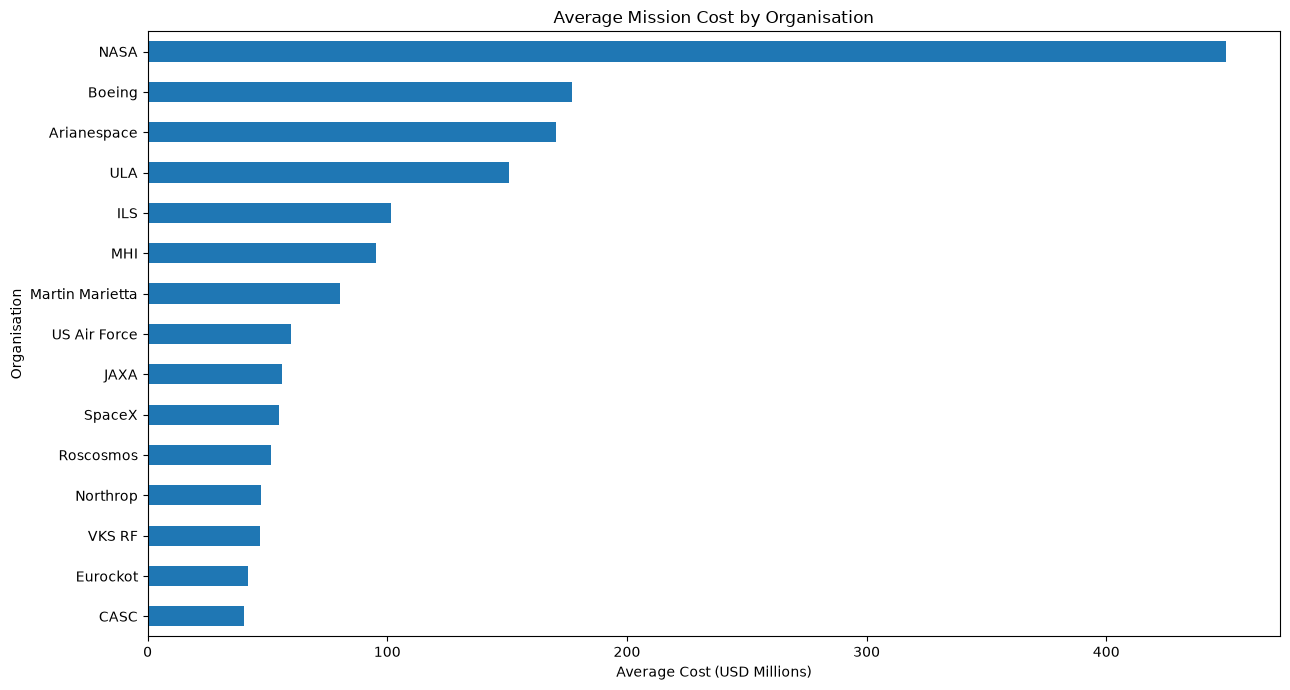

In [87]:
plt.figure(figsize=(13, 7))

organisation_avg_cost.head(15).sort_values().plot(kind='barh')

plt.title('Average Mission Cost by Organisation')
plt.xlabel('Average Cost (USD Millions)')
plt.ylabel('Organisation')

plt.tight_layout()
plt.show()

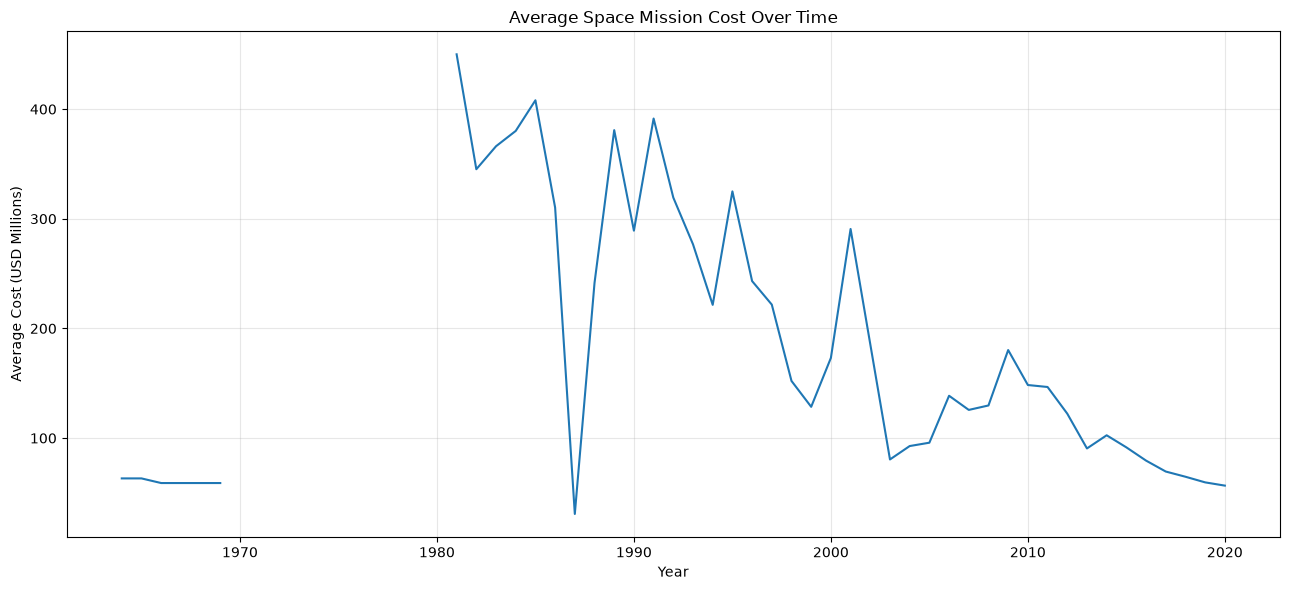

In [90]:
yearly_cost = df_data.groupby('Year')['Price'].mean()

plt.figure(figsize=(13, 6))

plt.plot(yearly_cost.index, yearly_cost.values)

plt.title('Average Space Mission Cost Over Time')
plt.xlabel('Year')
plt.ylabel('Average Cost (USD Millions)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Chart the Number of Launches per Year

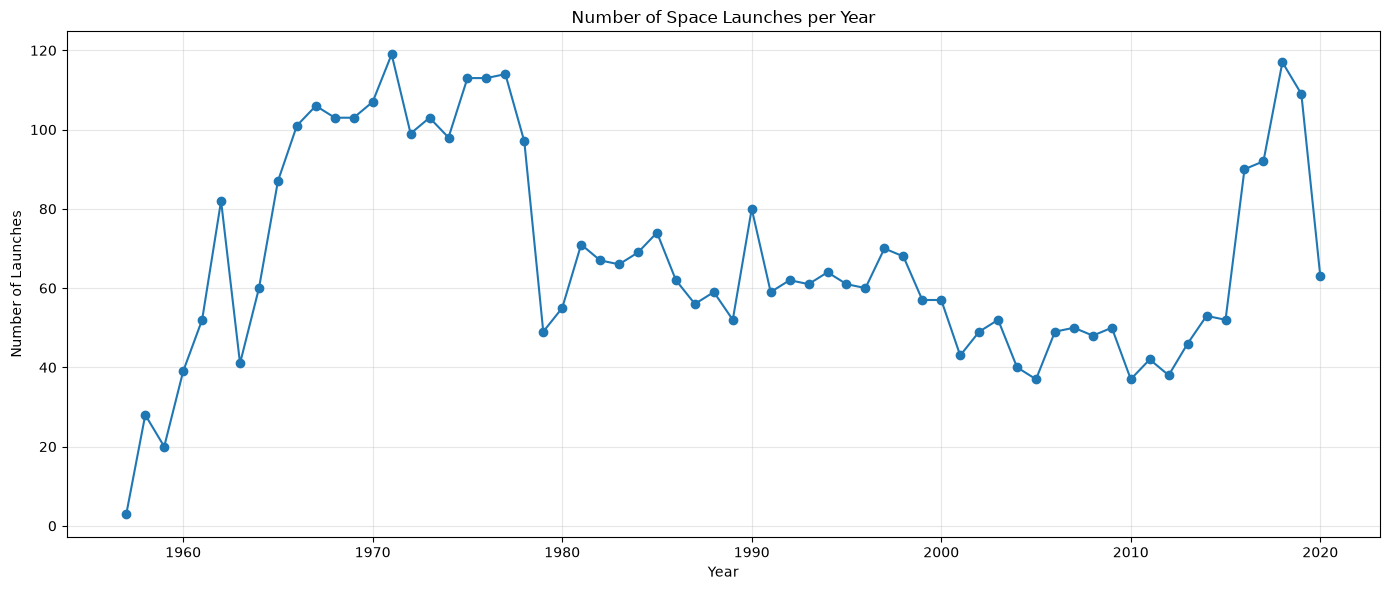

In [91]:
yearly_launches = df_data.groupby('Year').size()

plt.figure(figsize=(14, 6))

plt.plot(yearly_launches.index, yearly_launches.values, marker='o')

plt.title('Number of Space Launches per Year')
plt.xlabel('Year')
plt.ylabel('Number of Launches')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart the Number of Launches Month-on-Month until the Present

Which month has seen the highest number of launches in all time? Superimpose a rolling average on the month on month time series chart. 

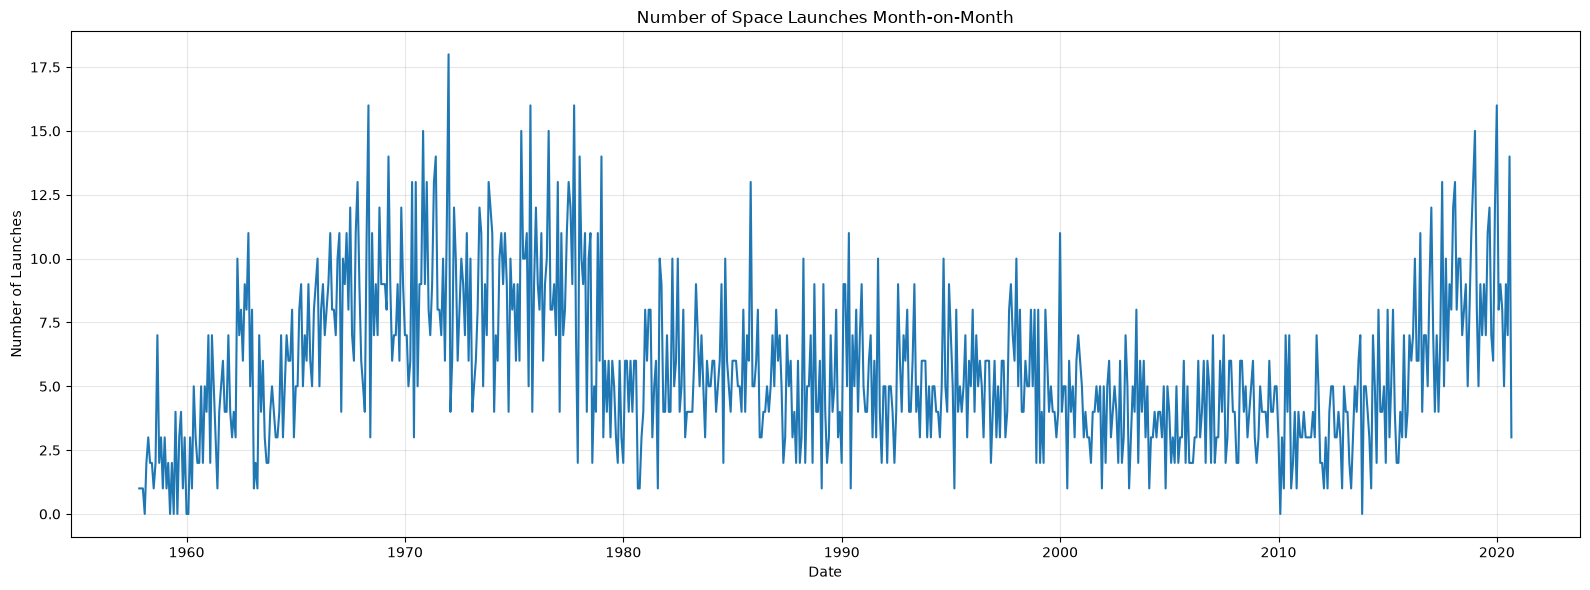

In [92]:
# Count launches month-on-month
monthly_launches = (
    df_data.set_index('Date')
    .resample('ME')
    .size()
)

plt.figure(figsize=(16, 6))

plt.plot(monthly_launches.index, monthly_launches.values)

plt.title('Number of Space Launches Month-on-Month')
plt.xlabel('Date')
plt.ylabel('Number of Launches')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Launches per Month: Which months are most popular and least popular for launches?

Some months have better weather than others. Which time of year seems to be best for space missions?

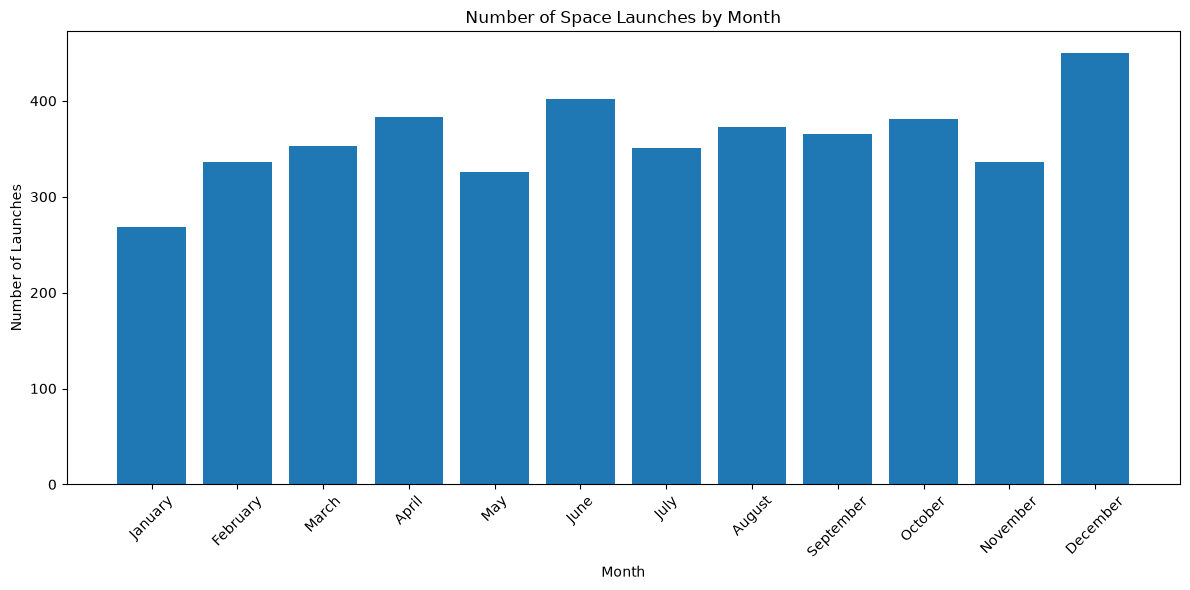

Most popular month: December
Least popular month: January


In [93]:
monthly_launches = df_data['Month'].value_counts().sort_index()

month_names = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

plt.figure(figsize=(12, 6))

plt.bar(month_names, monthly_launches.values)

plt.title('Number of Space Launches by Month')
plt.xlabel('Month')
plt.ylabel('Number of Launches')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print("Most popular month:", month_names[monthly_launches.values.argmax()])
print("Least popular month:", month_names[monthly_launches.values.argmin()])

# How has the Launch Price varied Over Time? 

Create a line chart that shows the average price of rocket launches over time. 

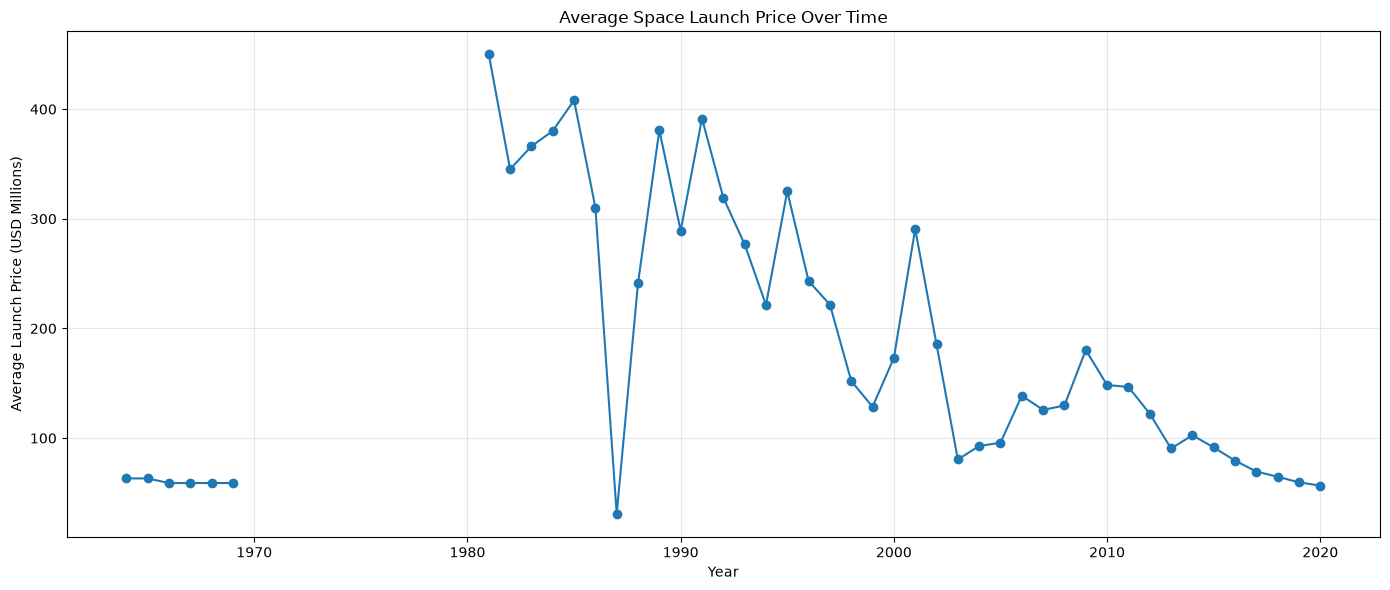

In [94]:
yearly_price = df_data.groupby('Year')['Price'].mean()

plt.figure(figsize=(14, 6))

plt.plot(yearly_price.index, yearly_price.values, marker='o')

plt.title('Average Space Launch Price Over Time')
plt.xlabel('Year')
plt.ylabel('Average Launch Price (USD Millions)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart the Number of Launches over Time by the Top 10 Organisations. 

How has the dominance of launches changed over time between the different players? 

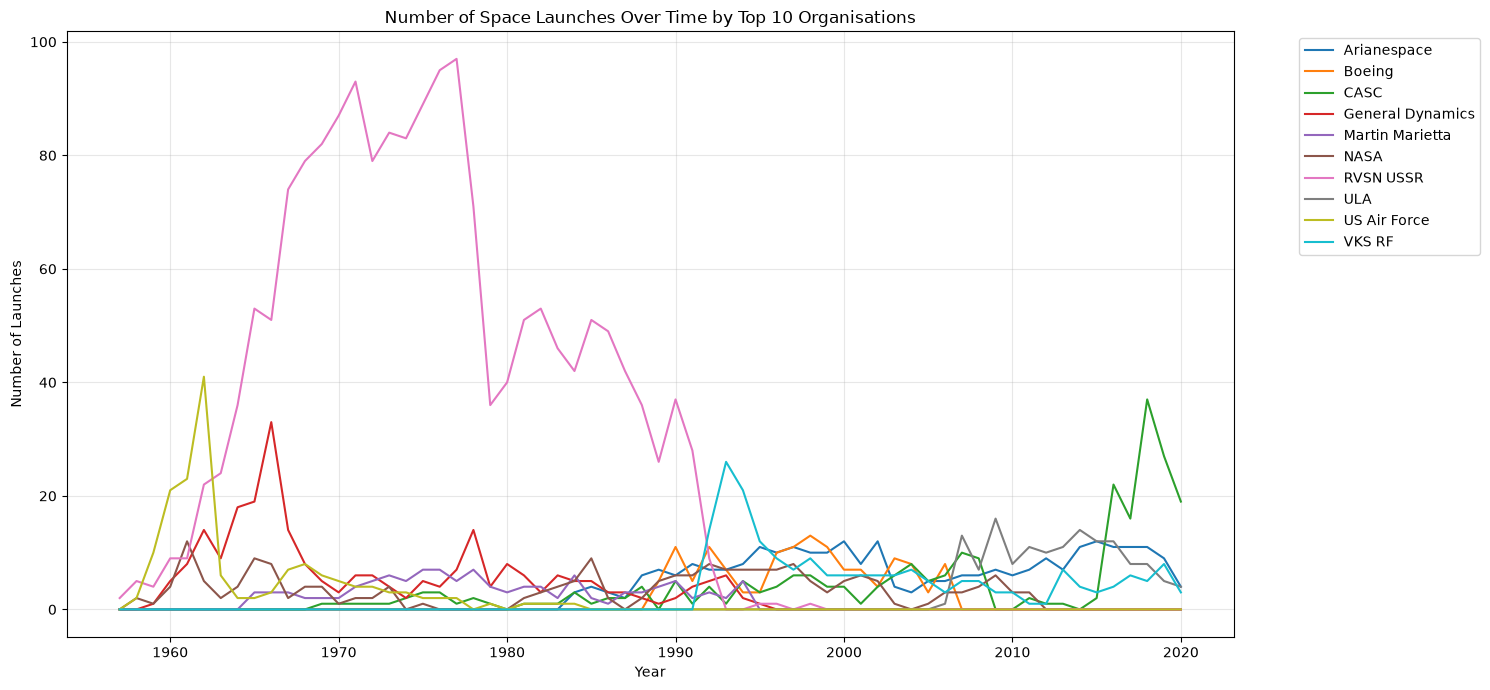

In [95]:
top_10_orgs = df_data['Organisation'].value_counts().head(10).index

org_yearly_launches = (
    df_data[df_data['Organisation'].isin(top_10_orgs)]
    .groupby(['Year', 'Organisation'])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(15, 7))

for org in org_yearly_launches.columns:
    plt.plot(
        org_yearly_launches.index,
        org_yearly_launches[org],
        label=org
    )

plt.title('Number of Space Launches Over Time by Top 10 Organisations')
plt.xlabel('Year')
plt.ylabel('Number of Launches')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Cold War Space Race: USA vs USSR

The cold war lasted from the start of the dataset up until 1991. 

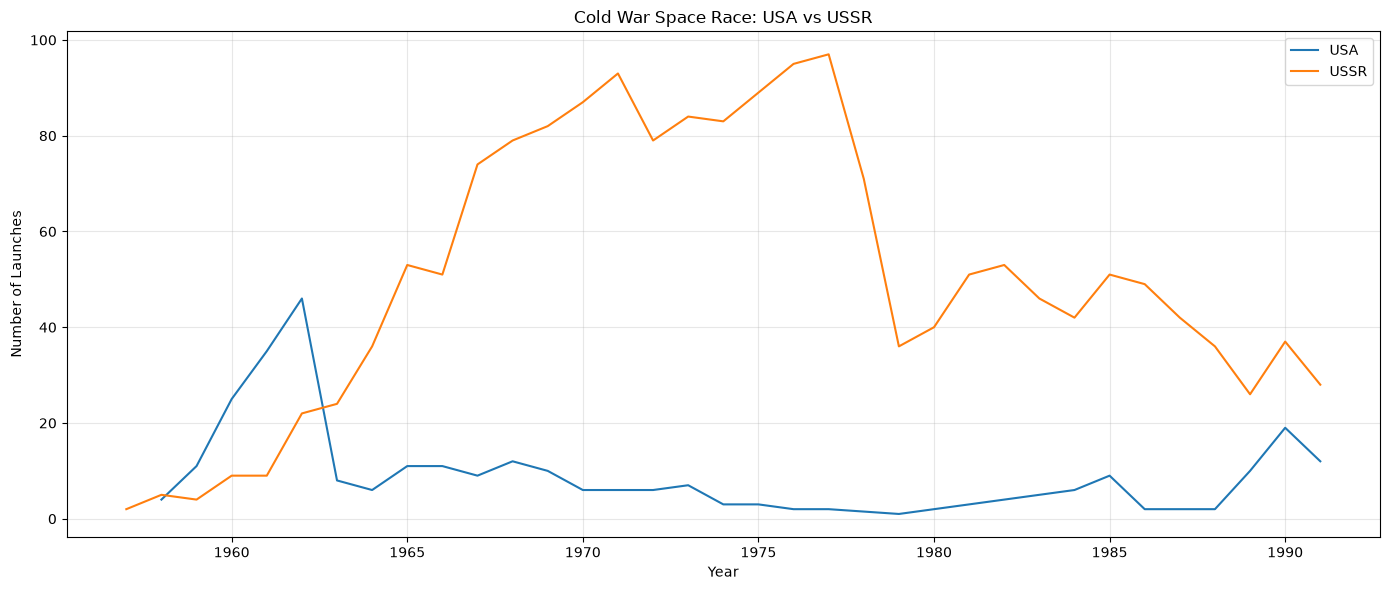

In [96]:
# Filter Cold War period (1947–1991)
cold_war = df_data[
    (df_data['Year'] >= 1947) &
    (df_data['Year'] <= 1991)
].copy()

# Identify USA and USSR organisations
usa_orgs = [
    'NASA',
    'US Air Force',
    'ULA',
    'Boeing',
    'Northrop',
    'Lockheed'
]

ussr_orgs = [
    'RVSN USSR',
    'VKS RF'
]

# Count launches
usa_launches = cold_war[
    cold_war['Organisation'].isin(usa_orgs)
].groupby('Year').size()

ussr_launches = cold_war[
    cold_war['Organisation'].isin(ussr_orgs)
].groupby('Year').size()

# Plot comparison
plt.figure(figsize=(14, 6))

plt.plot(usa_launches.index, usa_launches.values, label='USA')
plt.plot(ussr_launches.index, ussr_launches.values, label='USSR')

plt.title('Cold War Space Race: USA vs USSR')
plt.xlabel('Year')
plt.ylabel('Number of Launches')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Create a Plotly Pie Chart comparing the total number of launches of the USSR and the USA

Hint: Remember to include former Soviet Republics like Kazakhstan when analysing the total number of launches. 

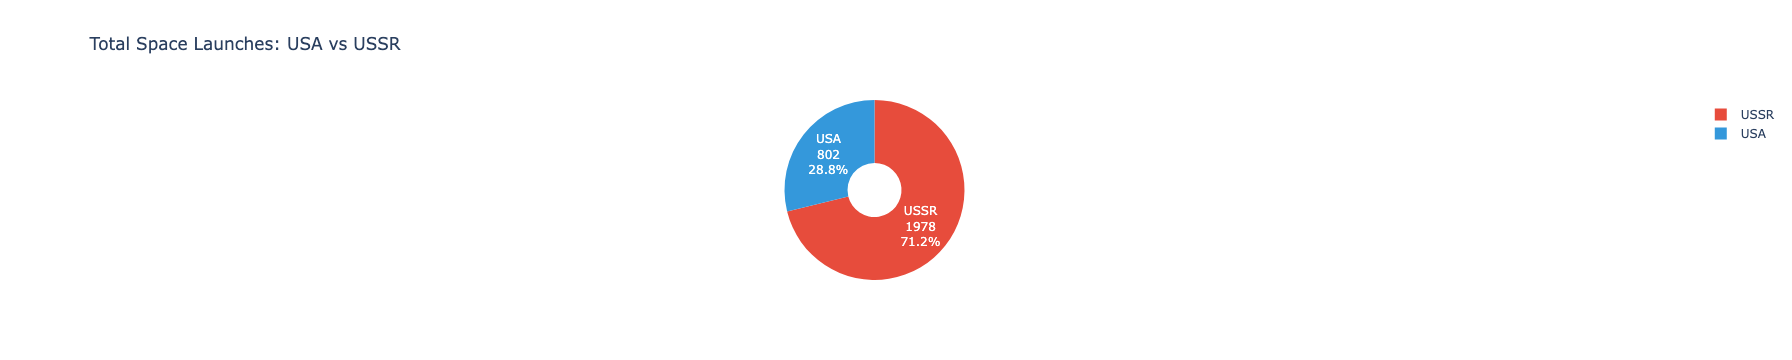

In [98]:
import plotly.express as px
import pandas as pd

usa_orgs = ['NASA', 'US Air Force', 'ULA', 'Boeing', 'Northrop', 'Lockheed']
ussr_orgs = ['RVSN USSR', 'VKS RF']

usa_total = df_data[df_data['Organisation'].isin(usa_orgs)].shape[0]
ussr_total = df_data[df_data['Organisation'].isin(ussr_orgs)].shape[0]

space_race_data = pd.DataFrame({
    'Country': ['USA', 'USSR'],
    'Total Launches': [usa_total, ussr_total]
})

fig = px.pie(
    space_race_data,
    names='Country',
    values='Total Launches',
    title='Total Space Launches: USA vs USSR',
    color='Country',
    color_discrete_map={'USA': '#3498DB', 'USSR': '#E74C3C'},
    hole=0.3
)

fig.update_traces(textinfo='label+value+percent')
fig.show(renderer='browser)

## Create a Chart that Shows the Total Number of Launches Year-On-Year by the Two Superpowers

In [99]:
superpowers = {
    'USA': usa_orgs,
    'USSR': ussr_orgs
}

yearly_superpower_launches = pd.DataFrame({
    country: (
        df_data[df_data['Organisation'].isin(orgs)]
        .groupby('Year').size()
    )
    for country, orgs in superpowers.items()
}).fillna(0)

fig = px.line(
    yearly_superpower_launches,
    x=yearly_superpower_launches.index,
    y=['USA', 'USSR'],
    title='Year-on-Year Space Launches: USA vs USSR',
    labels={
        'x': 'Year',
        'value': 'Number of Launches',
        'variable': 'Superpower'
    },
    markers=True,
    color_discrete_map={
        'USA': '#3498DB',
        'USSR': '#E74C3C'
    }
)

fig.show(renderer='browser')

## Chart the Total Number of Mission Failures Year on Year.

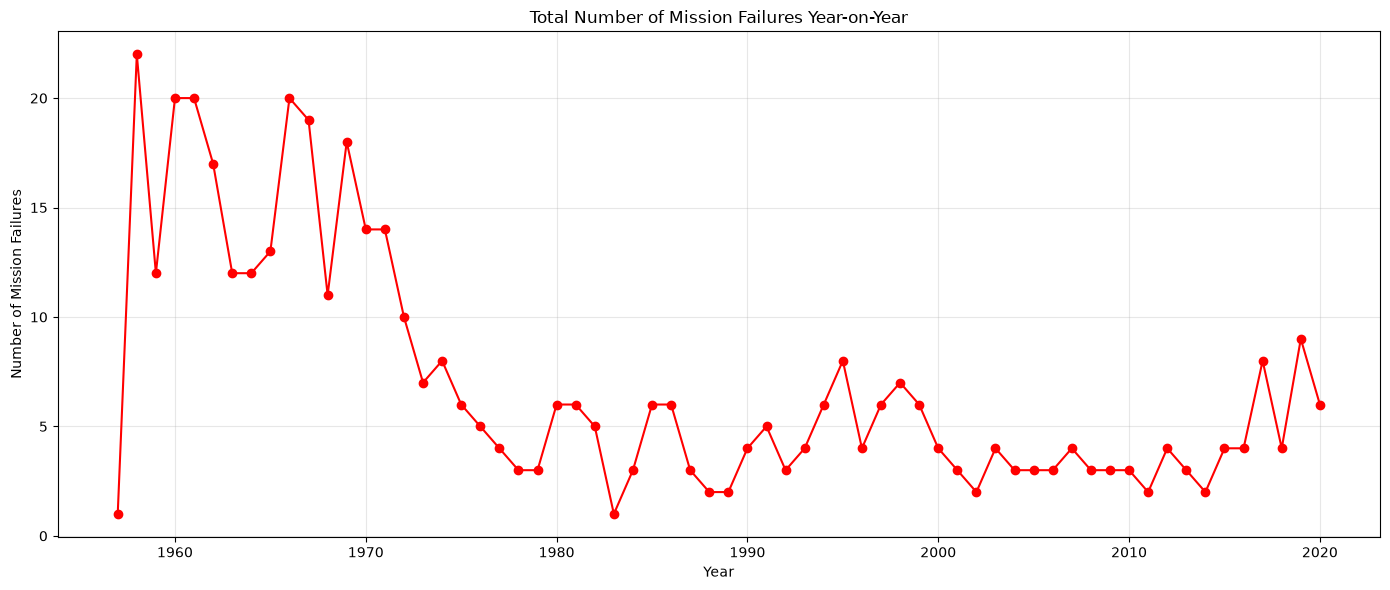

In [100]:
mission_failures = df_data[
    df_data['Mission_Status'] != 'Success'
]

yearly_failures = (
    mission_failures.groupby('Year').size()
)

plt.figure(figsize=(14, 6))
plt.plot(
    yearly_failures.index,
    yearly_failures.values,
    marker='o',
    color='red'
)

plt.title('Total Number of Mission Failures Year-on-Year')
plt.xlabel('Year')
plt.ylabel('Number of Mission Failures')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Chart the Percentage of Failures over Time

Did failures go up or down over time? Did the countries get better at minimising risk and improving their chances of success over time? 

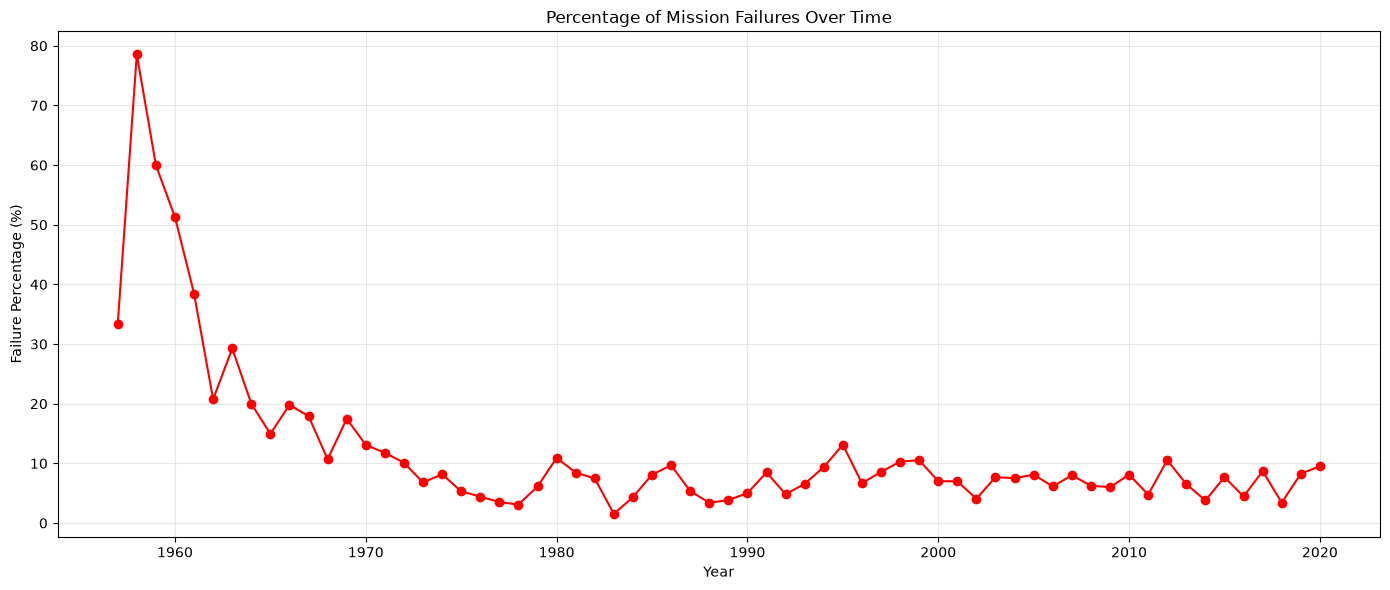

In [101]:
yearly_failure_percentage = (
    df_data.assign(
        Failed=df_data['Mission_Status'] != 'Success'
    )
    .groupby('Year')['Failed']
    .mean() * 100
)

plt.figure(figsize=(14, 6))
plt.plot(
    yearly_failure_percentage.index,
    yearly_failure_percentage.values,
    marker='o',
    color='red'
)

plt.title('Percentage of Mission Failures Over Time')
plt.xlabel('Year')
plt.ylabel('Failure Percentage (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# For Every Year Show which Country was in the Lead in terms of Total Number of Launches up to and including including 2020)

Do the results change if we only look at the number of successful launches? 

In [102]:
country_yearly_launches = (
    df_data[
        (df_data['Year'] <= 2020) &
        (df_data['Country_Clean'].notna())
    ]
    .groupby(['Year', 'Country_Clean'])
    .size()
    .reset_index(name='Total_Launches')
)

yearly_leaders = (
    country_yearly_launches
    .sort_values(['Year', 'Total_Launches'], ascending=[True, False])
    .drop_duplicates(subset='Year')
    .reset_index(drop=True)
)

print(yearly_leaders.to_string(index=False))

fig = px.bar(
    yearly_leaders,
    x='Year',
    y='Total_Launches',
    color='Country_Clean',
    title='Leading Country in Space Launches Each Year (1957–2020)',
    labels={
        'Year': 'Year',
        'Total_Launches': 'Number of Launches',
        'Country_Clean': 'Country'
    },
    hover_data=['Country_Clean']
)

fig.update_layout(
    xaxis=dict(dtick=5),
    width=1200,
    height=600
)

fig.show(renderer='browser')

 Year Country_Clean  Total_Launches
 1957    Kazakhstan               2
 1958           USA              23
 1959           USA              16
 1960           USA              30
 1961           USA              43
 1962           USA              60
 1963           USA              17
 1964    Kazakhstan              28
 1965    Kazakhstan              43
 1966           USA              47
 1967    Kazakhstan              38
 1968    Kazakhstan              40
 1969        Russia              45
 1970        Russia              59
 1971        Russia              62
 1972        Russia              57
 1973        Russia              67
 1974        Russia              60
 1975        Russia              66
 1976        Russia              66
 1977        Russia              72
 1978        Russia              62
 1979        Russia              33
 1980        Russia              34
 1981        Russia              41
 1982        Russia              43
 1983        Russia         

# Create a Year-on-Year Chart Showing the Organisation Doing the Most Number of Launches

Which organisation was dominant in the 1970s and 1980s? Which organisation was dominant in 2018, 2019 and 2020? 

In [103]:
yearly_org_launches = (
    df_data.groupby(['Year', 'Organisation'])
    .size()
    .reset_index(name='Total_Launches')
)

yearly_org_leaders = (
    yearly_org_launches
    .sort_values(['Year', 'Total_Launches'], ascending=[True, False])
    .drop_duplicates(subset='Year')
    .sort_values('Year')
)

fig = px.bar(
    yearly_org_leaders,
    x='Year',
    y='Total_Launches',
    color='Organisation',
    title='Organisation with the Most Space Launches Each Year',
    labels={
        'Year': 'Year',
        'Total_Launches': 'Number of Launches',
        'Organisation': 'Leading Organisation'
    },
    hover_data=['Organisation']
)

fig.update_layout(
    xaxis=dict(dtick=5),
    width=1200,
    height=600
)

fig.show(renderer='browser')